In [1]:
import os
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

In [4]:
pth = os.path.join('..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'CCCA')
pth_dev = os.path.join(pth_data, 'development', 'modeling')
# pth_out = os.path.join(pth, 'figures', 'mesencoder', 'bifurcation')

In [5]:
adata_dev = sc.read_h5ad(os.path.join(pth_dev, 'bifurcation.h5ad'))
adata = sc.read_h5ad(os.path.join(pth_in, 'bifurcation.h5ad'))
adata

AnnData object with n_obs × n_vars = 149645 × 510
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores'

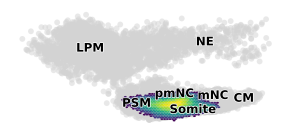

In [18]:
# plot density (hexbin)
nx, figsize = 100, (3.5, 1.5)
fig, ax = plt.subplots(1, 1, figsize = figsize)
sc.pl.embedding(adata_dev, 'X_mesencoder', dimensions = [1, 0],
                size = 70, alpha = .5, frameon = False,
                show = False, ax = ax)
xlim = ax.get_xlim(); ylim = ax.get_ylim()
y, x = adata.obsm['X_mesencoder'].T
ar_data = (xlim[1] - xlim[0]) / (ylim[1] - ylim[0])
ar_fig = (figsize[0] / figsize[1])
ny = int((nx / np.sqrt(3)) * (ar_data / ar_fig))
hb = ax.hexbin(x, y, gridsize = [nx, ny], bins = 'log',
               extent = [*xlim, *ylim], cmap = 'viridis',
               linewidths = 0, mincnt = 45)
sc.pl.embedding(adata_dev, 'X_mesencoder', dimensions = [1, 0],
                size = 70, alpha = 0, color = 'celltype',
                legend_loc = 'on data', legend_fontsize = 8.5,
                legend_fontoutline = 1, frameon = False,
                show = False, ax = ax)
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_title(''); ax.invert_yaxis()

label_dict = {
    'Cranial Mesenchyme'         : 'CM',
    'Lateral Plate Mesoderm'     : 'LPM',
    'Migratory Neural Crest'     : 'mNC',
    'nan'                        : '',
    'Nascent Endothelium'        : 'NE',
    'Neuroglial Progenitors'     : '',
    'Neuromesodermal Progenitor' : '',
    'Premigratory Neural Crest'  : 'pmNC',
    'Presomitic Mesoderm'        : 'PSM'}

pos_dict = {
    'Cranial Mesenchyme'        : (.15, -.05),
    'Lateral Plate Mesoderm'    : (-.2, 0),
    'Migratory Neural Crest'    : (.125, .025),
    'Premigratory Neural Crest' : (.125, -.15),
    'Presomitic Mesoderm'       : (-.315, .115),
    'Somite'                    : (-.175, .075)}

for label in ax.texts:
    _label_ = label.get_text()
    x, y = label.get_position()
    if _label_ in label_dict:
        label.set_text(label_dict[_label_])
    if _label_ in pos_dict:
        dx, dy = pos_dict[_label_]
        label.set_position([x + dx, y + dy])

fn = os.path.join(pth_out, 'CCCA.pdf')
plt.savefig(fn, bbox_inches = 'tight')

/tmp/ipykernel_3419344/1653327758.py:3: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(hb, cax = cax)


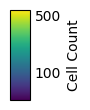

In [25]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(hb, cax = cax)
cb.set_ticks([100, 500])
cb.ax.tick_params(which = 'both', size = 0)
fmt = ticker.FormatStrFormatter('%g')
cb.ax.yaxis.set_major_formatter(fmt)
cb.set_label('Cell Count')
fn = os.path.join(pth_out, 'colorbar.pdf')
plt.savefig(fn, bbox_inches = 'tight')